# Violencia global e porte civil de armas

## Etapa inicial: EDA e pre-processamento
Primeiramente, vamos fazer a etapa inicial do trabalho, antes de obviamente começar com as etapas de machine learning: entendimento das quatro bases, analise exploratoria, verificação de qualidade e preparação de uma base limpa

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)

## 1. Carga e descrição das bases

In [3]:
arquivos = {
    'porte_civil_2017': 'civilian_firearms_2017.csv',
    'perfil_pais': 'country_gun_profile.csv',
    'homicidios_anuais': 'firearm_homicides_country_year.csv',
    'serie_historica_europa': 'homicide_long_run_western_europe.csv'
}
bases = {nome: pd.read_csv(arquivo) for nome, arquivo in arquivos.items()}

resumo_bases = pd.DataFrame([
    {'base': nome, 'linhas': base.shape[0], 'colunas': base.shape[1],
     'periodo': f"{base['year'].min()} - {base['year'].max()}" if 'year' in base else '2017'}
    for nome, base in bases.items()
])
display(resumo_bases)

df = bases['homicidios_anuais'].copy()
display(df.head())
df.info()

,base,linhas,colunas,periodo
0,porte_civil_2017,230,10,2017
1,perfil_pais,217,20,2017
2,homicidios_anuais,3120,24,2000 - 2024
3,serie_historica_europa,751,5,1250 - 2023


,iso3,country,region,income_group,year,homicide_rate,homicides,homicides_total_est,firearm_homicide_rate,firearm_homicides,firearm_share_of_homicides_pct,female_homicide_rate,male_homicide_rate,ipv_female_victim_rate,ipv_male_victim_rate,seized_arms_illicit_origin_pct,population,gdp_per_capita_usd,gini_index,unemployment_pct,urban_population_pct,male_15_64_share_pct,military_spending_pct_gdp,secondary_school_enrollment_pct
0,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2009,4.060,1115.0,1115.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27466101,452.05,NaN,7.81,21.69,24.34,2.09,44.30
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2010,3.475,983.0,983.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28284089,560.62,NaN,7.81,22.26,24.57,1.95,50.44
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2011,4.195,1231.0,1231.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29347708,606.69,NaN,7.83,22.82,24.81,1.82,52.45
3,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2012,6.374,1948.0,1948.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30560034,651.42,NaN,7.88,23.34,25.05,1.18,54.37
4,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2015,9.952,3367.0,3367.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33831764,565.57,NaN,9.03,24.46,25.80,0.99,53.15


<class 'pandas.DataFrame'>
RangeIndex: 3120 entries, 0 to 3119
Data columns (total 24 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   iso3                             3120 non-null   str    
 1   country                          3120 non-null   str    
 2   region                           3120 non-null   str    
 3   income_group                     3120 non-null   str    
 4   year                             3120 non-null   int64  
 5   homicide_rate                    3104 non-null   float64
 6   homicides                        3104 non-null   float64
 7   homicides_total_est              3104 non-null   float64
 8   firearm_homicide_rate            1053 non-null   float64
 9   firearm_homicides                1053 non-null   float64
 10  firearm_share_of_homicides_pct   1026 non-null   float64
 11  female_homicide_rate             2211 non-null   float64
 12  male_homicide_rate             

A base escolhida possui uma observação por país e ano, de 2000 a 2024. As demais fontes podem ser aproveitadas mais tarde em análises complementares, mas nao serao mescladas agora, pois algumas são retratos de 2017 e outra base possui uma escala histórica muito diferente

## 2. Qualidade dos dados

,linhas_duplicadas,pais_ano_duplicados,paises,periodo
0,0,0,187,2000 - 2024


,n_ausente,pct_ausente,tipo
seized_arms_illicit_origin_pct,3026,97.0,float64
ipv_male_victim_rate,2372,76.0,float64
ipv_female_victim_rate,2345,75.2,float64
firearm_share_of_homicides_pct,2094,67.1,float64
firearm_homicides,2067,66.2,float64
firearm_homicide_rate,2067,66.2,float64
gini_index,1702,54.6,float64
male_homicide_rate,912,29.2,float64
female_homicide_rate,909,29.1,float64
secondary_school_enrollment_pct,710,22.8,float64


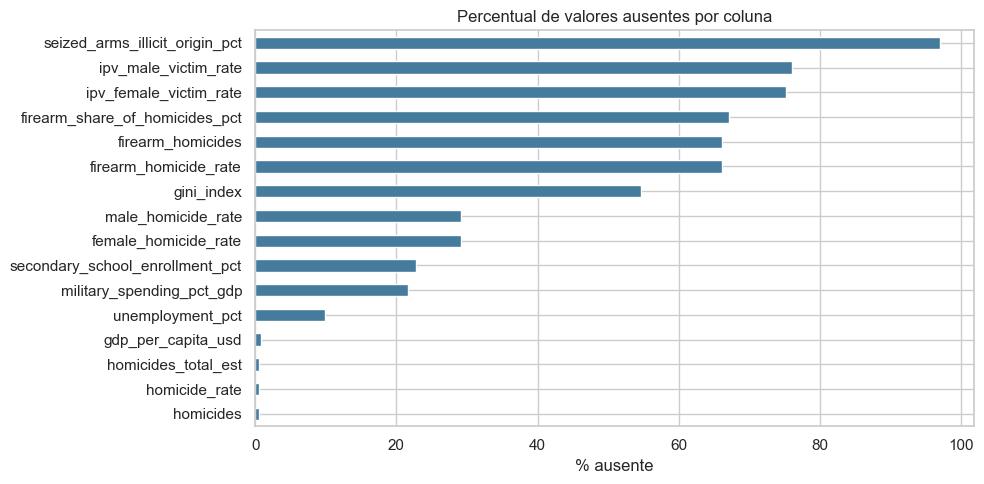

In [4]:
checagens = pd.DataFrame({
    'linhas_duplicadas': [df.duplicated().sum()],
    'pais_ano_duplicados': [df.duplicated(['iso3', 'year']).sum()],
    'paises': [df['iso3'].nunique()],
    'periodo': [f"{df['year'].min()} - {df['year'].max()}"]
})
display(checagens)

ausentes = pd.DataFrame({
    'n_ausente': df.isna().sum(),
    'pct_ausente': df.isna().mean().mul(100).round(1),
    'tipo': df.dtypes.astype(str)
}).sort_values('pct_ausente', ascending=False)
display(ausentes)

plt.figure(figsize=(10, 5))
ausentes.query('pct_ausente > 0')['pct_ausente'].sort_values().plot.barh(color='#457b9d')
plt.title('Percentual de valores ausentes por coluna')
plt.xlabel('% ausente'); plt.ylabel(''); plt.tight_layout()

A variavel `seized_arms_illicit_origin_pct` tem ausência muito elevada e será retirada da base limpa. Para as demais colunas, a ausência será preservada no diagnóstico e tratada adiante por mediana (numéricas) ou categoria `Desconhecido` (categóricas)

## 3. Analise exploratoria

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
iso3,3120,187,ALB,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,3120,187,Albania,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,3120,7,Europe & Central Asia,1052,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_group,3120,4,High income,1530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,3120.0,NaN,NaN,NaN,2011.263462,6.662174,2000.0,2006.0,2011.0,2017.0,2024.0
homicide_rate,3104.0,NaN,NaN,NaN,8.094443,12.176486,0.0,1.197,2.933,9.16,107.638
homicides,3104.0,NaN,NaN,NaN,2288.004832,7323.771339,0.0,34.0,187.0,776.0,63788.0
homicides_total_est,3104.0,NaN,NaN,NaN,2284.271263,7316.786888,0.0,33.0,183.5,776.0,63788.0
firearm_homicide_rate,1053.0,NaN,NaN,NaN,5.579905,10.968661,0.0,0.149,0.492,4.825,89.526
firearm_homicides,1053.0,NaN,NaN,NaN,930.146249,3062.797973,0.0,8.0,28.0,262.0,25867.0


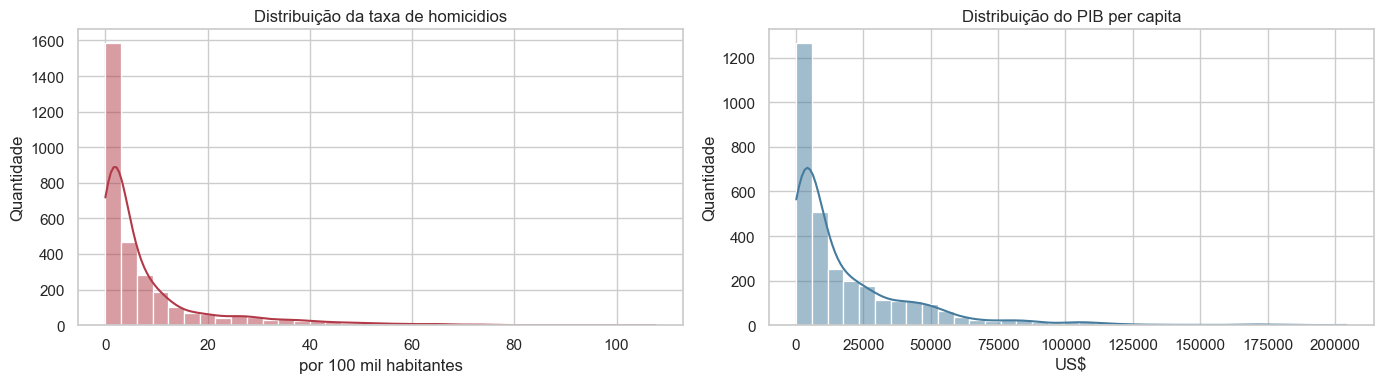

In [6]:
display(df.describe(include='all').T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['homicide_rate'].dropna(), bins=35, kde=True, color='#b23a48', ax=axes[0])
axes[0].set(title='Distribuição da taxa de homicidios', xlabel='por 100 mil habitantes', ylabel='Quantidade')
sns.histplot(df['gdp_per_capita_usd'].dropna(), bins=35, kde=True, color='#457b9d', ax=axes[1])
axes[1].set(title='Distribuição do PIB per capita', xlabel='US$', ylabel='Quantidade')
plt.tight_layout()

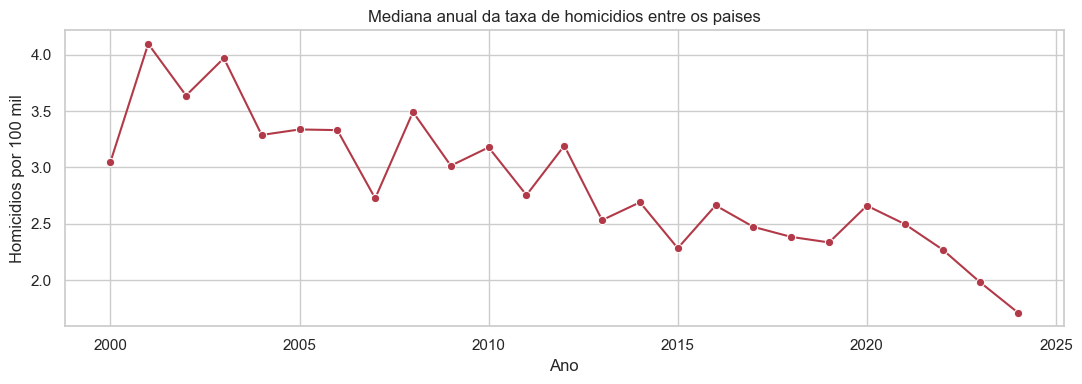

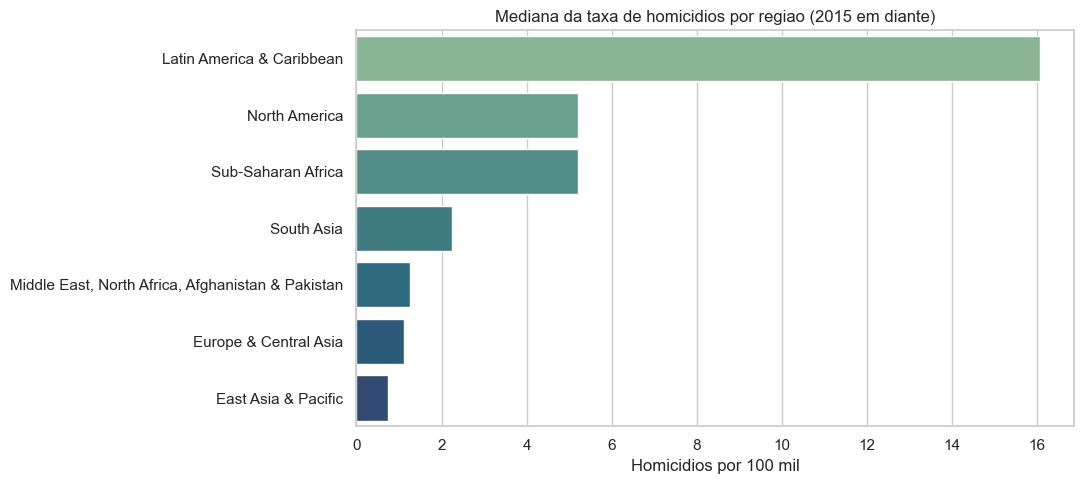

In [7]:
# A mediana limita a influência de poucos paises com valores muito altos
mediana_anual = df.groupby('year', as_index=False)['homicide_rate'].median()
plt.figure(figsize=(11, 4))
sns.lineplot(data=mediana_anual, x='year', y='homicide_rate', marker='o', color='#b23a48')
plt.title('Mediana anual da taxa de homicidios entre os paises')
plt.xlabel('Ano'); plt.ylabel('Homicidios por 100 mil'); plt.tight_layout()

regional = (df.query('year >= 2015').groupby('region', as_index=False)['homicide_rate']
            .median().sort_values('homicide_rate', ascending=False))
plt.figure(figsize=(11, 5))
sns.barplot(data=regional, y='region', x='homicide_rate', hue='region', legend=False, palette='crest')
plt.title('Mediana da taxa de homicidios por regiao (2015 em diante)')
plt.xlabel('Homicidios por 100 mil'); plt.ylabel(''); plt.tight_layout()

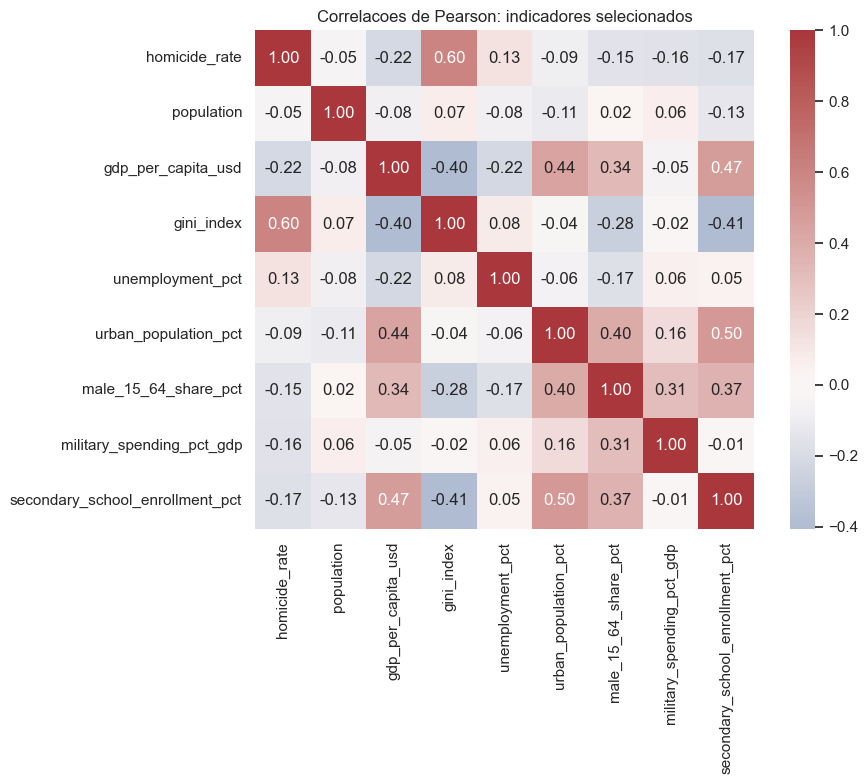

In [ ]:
numericas_eda = ['homicide_rate', 'population', 'gdp_per_capita_usd', 'gini_index',
                  'unemployment_pct', 'urban_population_pct', 'male_15_64_share_pct',
                  'military_spending_pct_gdp', 'secondary_school_enrollment_pct']
corr = df[numericas_eda].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap='vlag', center=0, annot=True, fmt='.2f', square=True)
plt.title('Correlações de Pearson: indicadores selecionados'); plt.tight_layout()

## 4. Identificacao de valores discrepantes

,coluna,limite_inferior,limite_superior,n_sinalizado
0,homicide_rate,-1.074750e+01,2.110450e+01,360
1,population,-3.637861e+07,6.397896e+07,336
2,gdp_per_capita_usd,-3.152507e+04,6.111483e+04,193
5,military_spending_pct_gdp,-1.075000e+00,4.325000e+00,158
4,unemployment_pct,-5.678750e+00,2.043125e+01,133
3,gini_index,1.410000e+01,5.790000e+01,12


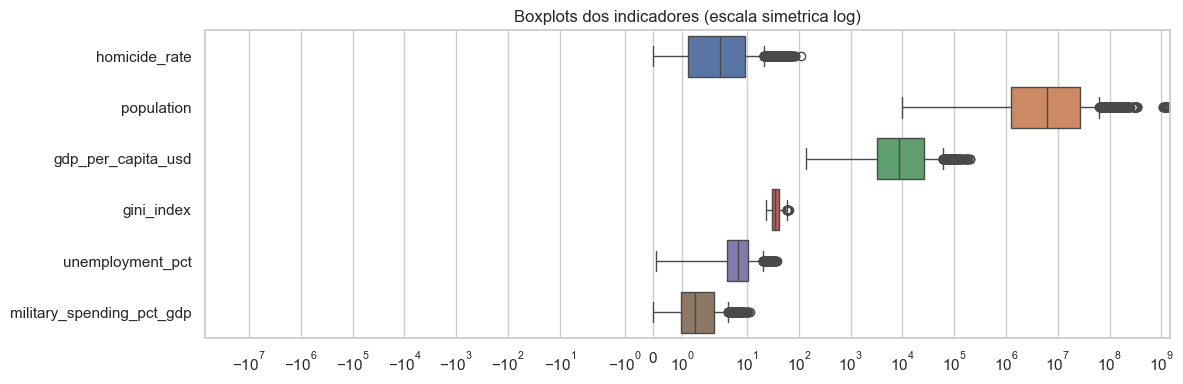

In [9]:
# Regra do intervalo interquartil (IQR), usada para sinalizar e nao para excluir automaticamente.
colunas_outlier = ['homicide_rate', 'population', 'gdp_per_capita_usd', 'gini_index',
                   'unemployment_pct', 'military_spending_pct_gdp']
linhas_outlier = []
for coluna in colunas_outlier:
    serie = df[coluna].dropna()
    q1, q3 = serie.quantile([.25, .75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    linhas_outlier.append({
        'coluna': coluna, 'limite_inferior': inferior, 'limite_superior': superior,
        'n_sinalizado': ((serie < inferior) | (serie > superior)).sum()
    })
display(pd.DataFrame(linhas_outlier).sort_values('n_sinalizado', ascending=False))

plt.figure(figsize=(12, 4))
sns.boxplot(data=df[colunas_outlier], orient='h', showfliers=True)
plt.xscale('symlog')
plt.title('Boxplots dos indicadores (escala simetrica log)'); plt.tight_layout()

Os valores sinalizados nao sao apagados: um pais com grande populacao, PIB ou taxa de homicidios pode representar um caso real e relevante. Nesta fase, a decisao e manter as observacoes e usar transformacoes logaritmicas nas variaveis muito assimetricas. Caso uma modelagem futura seja sensivel a extremos, os limites de winsorizacao deverao ser calculados apenas no conjunto de treino.

## 5. Base limpa e preparada para a proxima etapa

In [10]:
base_limpa = df.drop_duplicates().copy()
base_limpa = base_limpa.replace([np.inf, -np.inf], np.nan)

# Remove somente a coluna com cobertura insuficiente (mais de 95% ausente).
colunas_removidas = base_limpa.columns[base_limpa.isna().mean() > .95].tolist()
base_limpa = base_limpa.drop(columns=colunas_removidas)

colunas_numericas = base_limpa.select_dtypes(include='number').columns.tolist()
colunas_categoricas = base_limpa.select_dtypes(include='object').columns.tolist()

# Mediana e robusta a assimetria; categoria explicita evita perder linhas.
base_limpa[colunas_numericas] = base_limpa[colunas_numericas].fillna(base_limpa[colunas_numericas].median())
base_limpa[colunas_categoricas] = base_limpa[colunas_categoricas].fillna('Desconhecido')

# Novas escalas para duas variaveis fortemente assimetrica; os valores originais sao preservados.
base_limpa['log_population'] = np.log1p(base_limpa['population'])
base_limpa['log_gdp_per_capita_usd'] = np.log1p(base_limpa['gdp_per_capita_usd'])

print('Colunas removidas:', colunas_removidas)
print('Valores ausentes restantes:', base_limpa.isna().sum().sum())
display(base_limpa.head())

Colunas removidas: ['seized_arms_illicit_origin_pct']
Valores ausentes restantes: 0


C:\Users\endom\AppData\Local\Temp\ipykernel_9948\1893730202.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_categoricas = base_limpa.select_dtypes(include='object').columns.tolist()


,iso3,country,region,income_group,year,homicide_rate,homicides,homicides_total_est,firearm_homicide_rate,firearm_homicides,firearm_share_of_homicides_pct,female_homicide_rate,male_homicide_rate,ipv_female_victim_rate,ipv_male_victim_rate,population,gdp_per_capita_usd,gini_index,unemployment_pct,urban_population_pct,male_15_64_share_pct,military_spending_pct_gdp,secondary_school_enrollment_pct,log_population,log_gdp_per_capita_usd
0,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2009,4.060,1115.0,1115.0,0.492,28.0,29.515,1.245,3.7275,0.302,0.067,27466101,452.05,34.4,7.81,21.69,24.34,2.09,44.30,17.128463,6.116002
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2010,3.475,983.0,983.0,0.492,28.0,29.515,1.245,3.7275,0.302,0.067,28284089,560.62,34.4,7.81,22.26,24.57,1.95,50.44,17.157810,6.330825
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2011,4.195,1231.0,1231.0,0.492,28.0,29.515,1.245,3.7275,0.302,0.067,29347708,606.69,34.4,7.83,22.82,24.81,1.82,52.45,17.194725,6.409665
3,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2012,6.374,1948.0,1948.0,0.492,28.0,29.515,1.245,3.7275,0.302,0.067,30560034,651.42,34.4,7.88,23.34,25.05,1.18,54.37,17.235204,6.480689
4,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2015,9.952,3367.0,3367.0,0.492,28.0,29.515,1.245,3.7275,0.302,0.067,33831764,565.57,34.4,9.03,24.46,25.80,0.99,53.15,17.336911,6.339601
